In [1]:
import random
import sys
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn

In [2]:
SEED = 1337
torch.manual_seed(SEED)

try:
    ROOT = Path(__file__).resolve().parent
except NameError:  # exécution dans une cellule Jupyter : `__file__` n'existe pas
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
FIGURES_DIR = ROOT / "figures"
NAMES_URL = "https://raw.githubusercontent.com/karpathy/makemore/master/names.txt"

In [3]:
def load_text(path: Path, url: str) -> str:
    """Lit un fichier texte, en le téléchargeant d'abord s'il est absent."""
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        print(f"téléchargement de {url}")
        urllib.request.urlretrieve(url, path)
    return path.read_text(encoding="utf-8")

## 1. Les données

Même vocabulaire et même découpage 80 / 10 / 10 qu'au script 03 (même
graine de mélange). La façon de présenter les prénoms au réseau change, mais
elle dépend de ce que le réseau sait lire : on la verra au chapitre 4, une
fois la cellule récurrente construite.

In [4]:
words = load_text(DATA_DIR / "names.txt", NAMES_URL).splitlines()
chars = sorted(set("".join(words)))
stoi = {ch: i + 1 for i, ch in enumerate(chars)}
stoi["."] = 0
itos = {i: ch for ch, i in stoi.items()}
vocab_size = len(stoi)

random.seed(42)
random.shuffle(words)
n1, n2 = int(0.8 * len(words)), int(0.9 * len(words))

## 2. La cellule récurrente

À chaque pas de temps `t`, la cellule combine l'entrée courante `x_t` (son
embedding) et l'état précédent `h_{t-1}` :

     h_t = tanh(W_xh · x_t + W_hh · h_{t-1} + b)

puis prédit le caractère suivant à partir de `h_t` seul. **Tout** ce que le
modèle sait du passé doit tenir dans `h_t`. C'est un neurone,
avec une entrée de plus : sa propre sortie au pas précédent.

In [5]:
class CharRNN(nn.Module):
    """RNN caractère écrit à la main : embedding, cellule tanh, tête linéaire.

    Args:
        emb_dim: Dimension des embeddings de caractères.
        hidden: Taille de l'état caché.
    """

    def __init__(self, emb_dim: int = 16, hidden: int = 128) -> None:
        super().__init__()
        self.hidden = hidden
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.W_xh = nn.Linear(emb_dim, hidden)
        self.W_hh = nn.Linear(hidden, hidden, bias=False)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, x_t: torch.Tensor, h: torch.Tensor) -> torch.Tensor:
        """Un pas de temps : nouvel état caché à partir de l'entrée et de l'ancien état."""
        return torch.tanh(self.W_xh(self.emb(x_t)) + self.W_hh(h))

    def forward(self, x: torch.Tensor, h: torch.Tensor | None = None) -> tuple[torch.Tensor, list[torch.Tensor]]:
        """Déroule la cellule sur toute la séquence.

        Args:
            x: Indices, de forme `(B, T)`.
            h: État initial `(B, hidden)` ; des zéros s'il est absent.

        Returns:
            Les logits `(B, T, vocab_size)` et la liste des T états cachés.
        """
        B, T = x.shape
        if h is None:
            h = torch.zeros(B, self.hidden)
        states = []
        for t in range(T):
            h = self.step(x[:, t], h)
            states.append(h)
        logits = self.head(torch.stack(states, dim=1))
        return logits, states

## 3. Le déroulement dans le temps

La boucle `for t in range(T)` appelle **la même cellule**, avec **les mêmes
poids**, à chaque caractère. Si on écrit ces T appels l'un sous l'autre, on
obtient un réseau de T couches empilées : la sortie de chaque couche (`h_t`)
nourrit la suivante. Mais contrairement aux MLP de la séance 1, où chaque
couche avait ses propres poids, ici toutes les couches partagent le même `W`.

C'est l'idée de la convolution, transposée : le CNN applique le même filtre à
chaque position de l'image, le RNN applique la même cellule à chaque position
de la séquence. Une règle de lecture vaut à tout moment du texte.

Ainsi le nombre de paramètres ne dépend pas de la longueur de la séquence OoO.

In [6]:
model = CharRNN()
print(f"paramètres : {sum(p.numel() for p in model.parameters()):,}")
for T in [4, 16, 64]:
    logits, _ = model(torch.zeros(2, T, dtype=torch.long))
    print(f"séquence de {T:>2} : logits {tuple(logits.shape)}")

paramètres : 22,475
séquence de  4 : logits (2, 4, 27)
séquence de 16 : logits (2, 16, 27)
séquence de 64 : logits (2, 64, 27)


## 4. Les prénoms en un seul flux

Le MLP du script 03 imposait la forme des données : sa première couche
attend exactement 3 embeddings, donc chaque exemple était un couple
(3 caractères → suivant), et chaque prénom était traité à part.

Le RNN, lui, accepte une séquence de **n'importe quelle longueur** (on vient
de le voir avec T = 4, 16 et 64). Plus besoin de fabriquer des couples : on
met tous les prénoms bout à bout, séparés par `.`, en un seul long texte,
puis on y découpe des morceaux, exactement comme le texte de Shakespeare au
script 01. Le `.` garde son rôle des scripts 02 et 03 : il marque la fin
d'un prénom et le début du suivant.

Un morceau de `seq_len` caractères donne `seq_len` prédictions d'un coup :
la cible est le même morceau décalé d'un cran.

In [7]:
def to_stream(words_: list[str]) -> torch.Tensor:
    """Concatène des prénoms en un seul flux d'indices, séparés par `.`."""
    return torch.tensor([stoi[c] for c in "." + ".".join(words_) + "."])


train_stream = to_stream(words[:n1])
val_stream = to_stream(words[n1:n2])
print(f"flux train : {len(train_stream):,} caractères   val : {len(val_stream):,}")
print(f"début du flux : {''.join(itos[i] for i in train_stream[:60].tolist())}")

seq_len = 16


def get_batch(stream: torch.Tensor, batch_size: int) -> tuple[torch.Tensor, torch.Tensor]:
    """Tire des morceaux de `seq_len` caractères et leurs cibles décalées."""
    ix = torch.randint(len(stream) - seq_len - 1, (batch_size,))
    x = torch.stack([stream[i : i + seq_len] for i in ix])
    y = torch.stack([stream[i + 1 : i + seq_len + 1] for i in ix])
    return x, y


# un morceau pris au milieu du flux, et sa cible décalée d'un cran
x_demo, y_demo = train_stream[20 : 20 + seq_len], train_stream[21 : 21 + seq_len]
print(f"x : {''.join(itos[i] for i in x_demo.tolist())}")
print(f"y : {''.join(itos[i] for i in y_demo.tolist())}")

flux train : 182,626 caractères   val : 22,656
début du flux : .yuheng.diondre.xavien.jori.juanluis.erandi.phia.samatha.pho
x : en.jori.juanluis
y : n.jori.juanluis.


Le morceau commence au milieu d'un prénom et en contient plusieurs : ce
n'est pas un problème, le `.` indique au modèle où l'un finit et où l'autre
commence.

Attention à ne pas confondre `seq_len` avec la taille de contexte du
script 03. `block_size` était une contrainte du **modèle** : le MLP ne peut
pas lire autre chose que 3 caractères. `seq_len` est un choix
d'**entraînement** : la longueur des morceaux qu'on lui montre, réglée pour
le temps de calcul et la mémoire. Le même RNN lit ensuite des séquences de
n'importe quelle longueur, et à la génération, son état caché transporte
tout le passé (chapitre 6). La limite réelle est ailleurs : à
l'entraînement, l'état repart de zéro à chaque morceau, donc le modèle
n'apprend jamais de dépendance plus longue que 16 caractères. Pour des
prénoms, c'est largement suffisant.

## 5. Entraîner

La boucle de la séance 1, avec AdamW. Une nouveauté : le **gradient
clipping**. Avant chaque pas, si la norme du gradient dépasse un seuil (ici
1), on le rétrécit pour la ramener au seuil, sans changer sa direction. Un
RNN peut produire des gradients qui **explosent** : un seul pas
démesuré suffit à ruiner l'entraînement. Ici, le clipping ne se déclenchera
presque jamais ; c'est une assurance, standard pour tous les réseaux
récurrents, et elle ne coûte rien.

In [8]:
@torch.no_grad()
def evaluate(model_: nn.Module, stream: torch.Tensor, batches: int = 50) -> float:
    """Loss moyenne sur des morceaux tirés au hasard dans un flux."""
    g_state = torch.get_rng_state()
    torch.manual_seed(0)  # mêmes morceaux d'une évaluation à l'autre
    losses = []
    for _ in range(batches):
        x, y = get_batch(stream, 256)
        logits, _ = model_(x)
        losses.append(F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1)).item())
    torch.set_rng_state(g_state)
    return sum(losses) / len(losses)


def train(
    model_: nn.Module,
    steps: int = 4_000,
    batch_size: int = 64,
    lr: float = 3e-3,
    max_norm: float = 1.0,
    verbose: bool = True,
) -> list[float]:
    optimizer = torch.optim.AdamW(model_.parameters(), lr=lr)
    grad_norms = []
    for step in range(steps):
        x, y = get_batch(train_stream, batch_size)
        logits, _ = model_(x)
        loss = F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1))
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        norm = torch.nn.utils.clip_grad_norm_(model_.parameters(), max_norm)
        grad_norms.append(norm.item())
        optimizer.step()
        if verbose and step % 1_000 == 0:
            print(f"pas {step:>5} : loss {loss.item():.4f}")
    return grad_norms


grad_norms = train(model)
print(f"loss train : {evaluate(model, train_stream):.4f}   val : {evaluate(model, val_stream):.4f}")
print("MLP du script 03 (dim 10) : val ≈ 2.21")

clipped = sum(n > 1.0 for n in grad_norms)
print(f"norme du gradient : médiane {sorted(grad_norms)[len(grad_norms) // 2]:.2f}   max {max(grad_norms):.2f}")
print(f"pas où le clipping a servi : {clipped} sur {len(grad_norms):,}")

pas     0 : loss 3.3283
pas  1000 : loss 2.1557
pas  2000 : loss 2.1171
pas  3000 : loss 2.0792
loss train : 2.0268   val : 2.0968
MLP du script 03 (dim 10) : val ≈ 2.21
norme du gradient : médiane 0.41   max 0.66
pas où le clipping a servi : 0 sur 4,000


Ici, le clipping ne s'est **jamais** déclenché : la norme du gradient reste
sous le seuil du début à la fin. Avec 16 caractères par morceau et un état
borné par `tanh`, les gradients n'ont pas l'occasion d'exploser. C'est une
assurance, standard pour tous les réseaux récurrents : elle ne coûte rien
quand tout va bien, et elle évite qu'un seul mauvais lot ruine
l'entraînement quand les séquences s'allongent ou que le learning rate est
trop fort. Elle évite la catastrophe ; elle ne rend pas bon un mauvais
réglage.

Attention, la comparaison avec le MLP est approximative : ici les premiers
caractères de chaque morceau ont peu de contexte, et le RNN voit parfois la
fin du prénom précédent. L'essentiel est ailleurs : le RNN a appris **sans
qu'on fixe de taille de contexte**.

## 6. Générer

On ne ré-encode jamais le passé : on garde l'état caché et on avance d'un
caractère. Chaque pas coûte la même chose, quelle que soit la longueur déjà
générée.

In [9]:
g = torch.Generator().manual_seed(SEED)
with torch.no_grad():
    for _ in range(10):
        h = torch.zeros(1, model.hidden)
        ix, out = 0, []
        while True:
            h = model.step(torch.tensor([ix]), h)
            probs = F.softmax(model.head(h), dim=-1)
            ix = torch.multinomial(probs, 1, generator=g).item()
            if ix == 0 or len(out) > 30:
                break
            out.append(itos[ix])
        print("".join(out))

gun
katelia
deven
jaliyel
leahmarius
modarri
zanyn
vyblart
kaydrue
shaee


## 7. Le gradient qui s'évanouit

Le RNN promet un contexte illimité. En pratique, **peut-il apprendre** qu'un
caractère lu il y a 50 pas influence la prédiction actuelle ?

Expérience : une séquence de 60 caractères, une loss calculée **uniquement
sur la dernière prédiction**, et on mesure la norme du gradient de cette loss
par rapport à chaque état caché `h_t`. C'est le signal qui dit au réseau
comment `h_t` aurait dû être différent. S'il est nul, ce qui s'est passé au
temps `t` ne peut pas être appris.

Par la règle de la chaîne, remonter d'un pas multiplie le gradient par
`W_hh` et par la dérivée de `tanh` (toujours ≤ 1). Répété 60 fois, ce produit
tend vers zéro (ou explose, si `W_hh` est grand).

In [10]:
def gradient_through_time(states: list[torch.Tensor], loss: torch.Tensor) -> list[float]:
    """Norme de dL/dh_t pour chaque pas de temps.

    Args:
        states: États cachés, chacun avec `retain_grad()` activé.
        loss: Loss scalaire calculée à partir du dernier état.

    Returns:
        La norme du gradient pour chaque t.
    """
    loss.backward()
    return [h.grad.norm().item() for h in states]


torch.manual_seed(SEED)
LONG = 60
starts = torch.randint(len(val_stream) - LONG - 1, (32,))
long_x = torch.stack([val_stream[i : i + LONG] for i in starts])  # 32 séquences de 60 caractères
target = torch.stack([val_stream[i + LONG] for i in starts])  # le caractère qui suit chacune


def rnn_gradients(model_: CharRNN) -> list[float]:
    """Gradient de la loss du dernier pas par rapport à chaque état caché du RNN."""
    h = torch.zeros(long_x.shape[0], model_.hidden)
    states = []
    for t in range(long_x.shape[1]):
        h = model_.step(long_x[:, t], h)
        h.retain_grad()
        states.append(h)
    loss = F.cross_entropy(model_.head(states[-1]), target)
    return gradient_through_time(states, loss)


rnn_trained = rnn_gradients(model)
print(f"RNN entraîné : |dL/dh| au dernier pas {rnn_trained[-1]:.2e}   "
      f"10 pas avant {rnn_trained[-11]:.2e}   au premier pas {rnn_trained[0]:.2e}")

RNN entraîné : |dL/dh| au dernier pas 2.86e-01   10 pas avant 2.07e-03   au premier pas 1.76e-13


## 8. LSTM et GRU

Le **LSTM** (Hochreiter et Schmidhuber, 1997) ajoute à côté de l'état caché
une **cellule mémoire** `c_t`, mise à jour par **addition** plutôt que par
multiplication :

     c_t = f_t * c_{t-1} + i_t * g_t

Trois **portes** (des sigmoïdes entre 0 et 1) décident quoi oublier (`f_t`),
quoi écrire (`i_t`) et quoi exposer à la sortie (`o_t`). Quand la porte
d'oubli reste proche de 1, le gradient traverse la cellule sans être écrasé :
c'est une **autoroute** dans le temps, la même idée que la connexion
siduelle qu'on retrouvera dans le Transformer. Le **GRU** (2014) simplifie
le LSTM à deux portes.

On ne l'implémente pas : on prend `nn.LSTMCell`, on l'entraîne dans les mêmes
conditions, et on refait la mesure.

LSTM — loss train : 1.9075   val : 2.0562
LSTM entraîné : |dL/dh| au dernier pas 5.43e-01   10 pas avant 1.95e-02   au premier pas 5.81e-07


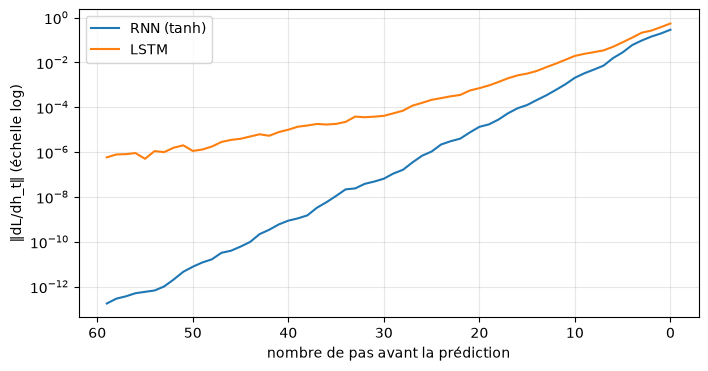

In [11]:
class CharLSTM(nn.Module):
    """Même modèle que `CharRNN`, avec une cellule LSTM de PyTorch."""

    def __init__(self, emb_dim: int = 16, hidden: int = 128) -> None:
        super().__init__()
        self.hidden = hidden
        self.emb = nn.Embedding(vocab_size, emb_dim)
        self.cell = nn.LSTMCell(emb_dim, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, list[torch.Tensor]]:
        B, T = x.shape
        h = c = torch.zeros(B, self.hidden)
        states = []
        for t in range(T):
            h, c = self.cell(self.emb(x[:, t]), (h, c))
            states.append(h)
        return self.head(torch.stack(states, dim=1)), states


lstm = CharLSTM()
train(lstm, verbose=False)
print(f"LSTM — loss train : {evaluate(lstm, train_stream):.4f}   val : {evaluate(lstm, val_stream):.4f}")


def lstm_gradients(model_: CharLSTM) -> list[float]:
    """Même mesure que `rnn_gradients`, pour le LSTM."""
    h = c = torch.zeros(long_x.shape[0], model_.hidden)
    states = []
    for t in range(long_x.shape[1]):
        h, c = model_.cell(model_.emb(long_x[:, t]), (h, c))
        h.retain_grad()
        states.append(h)
    loss = F.cross_entropy(model_.head(states[-1]), target)
    return gradient_through_time(states, loss)


lstm_trained = lstm_gradients(lstm)
print(f"LSTM entraîné : |dL/dh| au dernier pas {lstm_trained[-1]:.2e}   "
      f"10 pas avant {lstm_trained[-11]:.2e}   au premier pas {lstm_trained[0]:.2e}")


steps_back = list(range(len(rnn_trained) - 1, -1, -1))
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(steps_back, rnn_trained, label="RNN (tanh)")
ax.semilogy(steps_back, lstm_trained, label="LSTM")
ax.set_xlabel("nombre de pas avant la prédiction")
ax.set_ylabel("‖dL/dh_t‖ (échelle log)")
ax.invert_xaxis()
ax.legend()
ax.grid(alpha=0.3)


Les deux courbes descendent de façon exponentielle (une droite en échelle
log), mais le LSTM perd **beaucoup moins vite** : 60 pas en arrière, son
gradient est environ un million de fois plus fort que celui du RNN.

Honnêteté sur l'expérience : un prénom fait moins de 15 caractères, donc
rien ne pousse le réseau à se souvenir de 60 caractères. Une partie de la
décroissance est **apprise** (le passé lointain ne sert à rien ici). L'écart
entre les deux courbes, lui, vient de l'architecture. C'est pour cela que
les LSTM ont dominé le traitement du texte de 2014 à 2017 (traduction
automatique, reconnaissance vocale).


## 9. Ce qui reste

Même avec un LSTM, deux défauts sont **structurels** :

- **le goulot d'étranglement** : tout le passé doit tenir dans un vecteur de
  taille fixe. Pour traduire une phrase longue, le décodeur n'a que ce
  résumé ;
- **le calcul séquentiel** : `h_t` a besoin de `h_{t-1}`. Impossible de
   traiter les positions d'une séquence en parallèle, alors que les GPU
   excellent justement à tout faire en même temps.

L'**attention** (Bahdanau et al., 2014, puis *Attention is All You Need*,
2017) supprime les deux : chaque position va **chercher directement**
l'information dont elle a besoin dans toutes les positions précédentes, et
toutes les positions se calculent d'un coup. C'est le script 05.